# 04 · What makes a headline win? Explore, then confirm

Headline writers have folk rules: use numbers, ask a question, say "you", tease with "this". The archive lets us test these rules *within* experiments, comparing headlines written for the same story and shown to the same audience at the same time. That rules out most of the confounds that plague observational headline studies.

The archive was split by its authors into an **exploratory** and a **confirmatory** sample for this kind of work. We follow the protocol:

1. **Explore:** test 8 candidate features on the exploratory sample, with Benjamini–Hochberg correction across the 8.
2. **Pre-register:** carry forward only features with q < 0.10, *before* opening the confirmatory data.
3. **Confirm:** test only those features on the confirmatory sample, with Holm correction.

This is the multiple-comparison problem at the level of research findings. Fishing through features on one dataset makes some look predictive by chance. Replicating on fresh data is the cleanest defence.

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

from abtest import data, plotting as P

P.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RESULTS = {}

NEGATIVE = r"\b(?:worst|hate|never|wrong|sad|heartbreaking|terrible|awful|upsetting|horrible|scary|angry|fail\w*|dead|die\w*|kill\w*|cry\w*|disturbing|shocking)\b"

def headline_features(h: pd.Series) -> pd.DataFrame:
    s = h.str
    return pd.DataFrame({
        "number": s.contains(r"\d"),
        "question": s.contains(r"\?"),
        "exclamation": s.contains("!"),
        "you / your": s.contains(r"\b(?:you|your|you're|yourself)\b", case=False),
        "I / me / my": s.contains(r"\b(?:I|I'm|I've|I'd|me|my)\b"),
        "this / these / here's": s.contains(r"\b(?:this|these|here's)\b", case=False),
        "negative word": s.contains(NEGATIVE, case=False),
        "length (+10 words)": s.split().str.len() / 10,
    }, index=h.index).astype(float)

FEATURES = list(headline_features(pd.Series(["x"])).columns)
headline_features(pd.Series([
    "They're Just A Bunch Of Little Doodles In A Kid's Notebook. So Why Is It So Upsetting?",
    "There's Enough Of These Kids To Fill 223 Stadiums — And That's Not Even The Real Kicker Here",
]))

,number,question,exclamation,you / your,I / me / my,this / these / here's,negative word,length (+10 words)
0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.7000
1,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.8000


## Model: within-test weighted regression on log-odds

For arm *j* in test *t*, the outcome is the empirical log-odds of a click. Its sampling variance is about 1/clicks + 1/non-clicks, so arms are weighted by the inverse of that. Subtracting each test's weighted mean from both outcome and features (a **test fixed effect**) removes everything that is constant within a test: the story, the image, the day, the audience. What remains is the effect of *how the headline was written*. Standard errors are **clustered by test**, which also absorbs the extra-binomial noise found in notebook 02.

Coefficients are reported as **odds ratios**. At CTRs around 1%, these are almost exactly relative lifts in CTR.

In [2]:
def within_test_fit(arms: pd.DataFrame):
    X = headline_features(arms["headline"])
    c, n = arms["clicks"] + 0.5, arms["impressions"] + 1.0
    y = np.log(c / (n - c))
    w = 1 / (1 / c + 1 / (n - c))
    g = arms["test_id"]

    def demean(v):
        return v - (v.mul(w, axis=0).groupby(g).transform("sum")).div(w.groupby(g).transform("sum"), axis=0)

    Xd, yd = demean(X), demean(y.to_frame("y"))["y"]
    fit = sm.WLS(yd, Xd, weights=w).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(g)[0]})
    ci = fit.conf_int()
    out = pd.DataFrame({"odds_ratio": np.exp(fit.params), "or_lo": np.exp(ci[0]), "or_hi": np.exp(ci[1]),
                        "p": fit.pvalues})
    prevalence = X.gt(0).mean()
    out["share of headlines"] = prevalence.where(prevalence.index != "length (+10 words)", np.nan)
    return out, fit

explore_df = data.load_packages("exploratory")
explore_arms = data.headline_arms(explore_df)
print(f"Exploratory: {explore_arms.test_id.nunique():,} headline tests, {len(explore_arms):,} headlines")
explore, _ = within_test_fit(explore_arms)
explore["q_bh"] = multipletests(explore["p"], method="fdr_bh")[1]
explore["carry_forward"] = explore["q_bh"] < 0.10
explore

Exploratory: 1,825 headline tests, 8,354 headlines


,odds_ratio,or_lo,or_hi,p,share of headlines,q_bh,carry_forward
number,1.0579,1.0257,1.0910,0.0004,0.1712,0.0006,True
question,0.9165,0.8922,0.9414,0.0000,0.1709,0.0000,True
exclamation,0.8729,0.8148,0.9350,0.0001,0.0200,0.0003,True
you / your,0.9954,0.9686,1.0230,0.7427,0.2381,0.7427,False
I / me / my,1.0246,0.9909,1.0594,0.1545,0.0916,0.1766,False
this / these / here's,1.0389,1.0147,1.0637,0.0015,0.2837,0.0020,True
negative word,1.0679,1.0318,1.1053,0.0002,0.0937,0.0004,True
length (+10 words),1.1233,1.0853,1.1627,0.0000,NaN,0.0000,True


In [3]:
PREREGISTERED = explore.index[explore["carry_forward"]].tolist()
print("Pre-registered for confirmation:", PREREGISTERED)
RESULTS["preregistered"] = PREREGISTERED
RESULTS["explore"] = explore.reset_index(names="feature").to_dict(orient="records")

Pre-registered for confirmation: ['number', 'question', 'exclamation', "this / these / here's", 'negative word', 'length (+10 words)']


## Confirmation on the held-back sample

Only now do we load the confirmatory sample. The pre-registered features are tested with Holm correction. All 8 are estimated for transparency, but only the pre-registered ones count as confirmatory evidence.

In [4]:
confirm_df = data.load_packages("confirmatory")
confirm_arms = data.headline_arms(confirm_df)
print(f"Confirmatory: {confirm_arms.test_id.nunique():,} headline tests, {len(confirm_arms):,} headlines")
confirm, _ = within_test_fit(confirm_arms)
confirm["preregistered"] = confirm.index.isin(PREREGISTERED)
confirm["p_holm"] = np.nan
if PREREGISTERED:
    confirm.loc[PREREGISTERED, "p_holm"] = multipletests(confirm.loc[PREREGISTERED, "p"], method="holm")[1]
same_dir = np.sign(np.log(confirm["odds_ratio"])) == np.sign(np.log(explore["odds_ratio"]))
confirm["replicated"] = confirm["preregistered"] & (confirm["p_holm"] < 0.05) & same_dir
RESULTS["confirm"] = confirm.reset_index(names="feature").to_dict(orient="records")
confirm

Confirmatory: 8,794 headline tests, 40,442 headlines


,odds_ratio,or_lo,or_hi,p,share of headlines,preregistered,p_holm,replicated
number,1.0626,1.0474,1.0781,0.0000,0.1830,True,0.0000,True
question,0.9173,0.9056,0.9290,0.0000,0.1700,True,0.0000,True
exclamation,0.9400,0.9104,0.9707,0.0002,0.0210,True,0.0002,True
you / your,1.0077,0.9962,1.0193,0.1904,0.2446,False,NaN,False
I / me / my,1.0356,1.0195,1.0519,0.0000,0.0971,False,NaN,False
this / these / here's,1.0515,1.0402,1.0630,0.0000,0.2870,True,0.0000,True
negative word,1.0665,1.0497,1.0836,0.0000,0.0994,True,0.0000,True
length (+10 words),1.0978,1.0795,1.1164,0.0000,NaN,True,0.0000,True


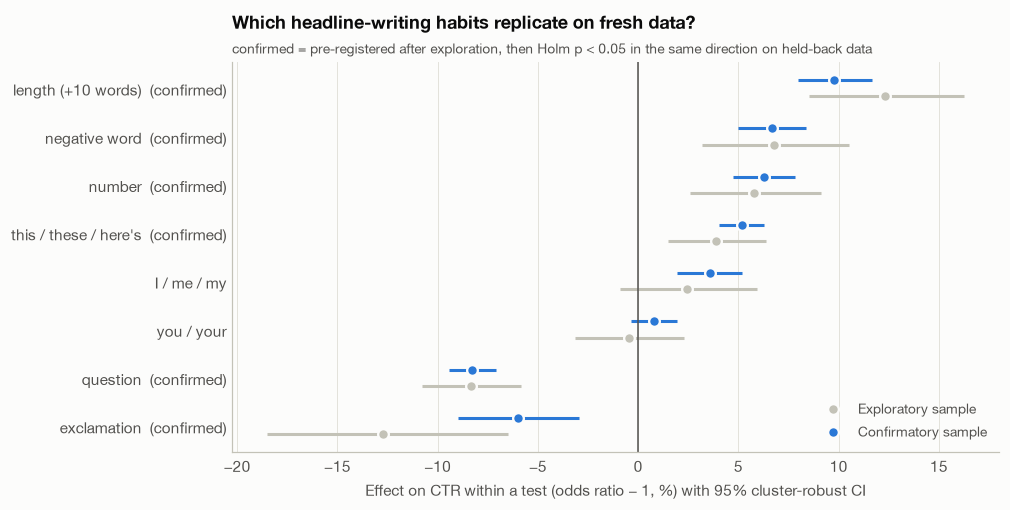

In [5]:
order = explore["odds_ratio"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 4.6))
for frame, name, color, off in [(explore, "Exploratory sample", P.CONTEXT, -0.17),
                                (confirm, "Confirmatory sample", P.BLUE, 0.17)]:
    f = frame.loc[order]
    ax.hlines(y + off, (f.or_lo - 1) * 100, (f.or_hi - 1) * 100, color=color, lw=2)
    ax.plot((f.odds_ratio - 1) * 100, y + off, "o", color=color, ms=7, mec=P.SURFACE, mew=1.5, label=name)
ax.axvline(0, color=P.INK_2, lw=1)
labels = [f"{feat}  (confirmed)" if confirm.loc[feat, "replicated"] else
          (f"{feat}  (pre-registered)" if feat in PREREGISTERED else feat) for feat in order]
ax.set_yticks(y, labels)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on CTR within a test (odds ratio − 1, %) with 95% cluster-robust CI")
ax.legend(loc="lower right")
ax.set_title("Which headline-writing habits replicate on fresh data?")
P.subtitle(ax, "confirmed = pre-registered after exploration, then Holm p < 0.05 in the same direction on held-back data")
P.save(fig, "14_headline_features")
plt.show()

In [6]:
summary = pd.DataFrame({
    "explore OR": explore["odds_ratio"], "explore q (BH)": explore["q_bh"],
    "confirm OR": confirm["odds_ratio"], "confirm p (Holm)": confirm["p_holm"],
    "replicated": confirm["replicated"],
})
with open("../reports/results/04_headline_features.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
summary

,explore OR,explore q (BH),confirm OR,confirm p (Holm),replicated
number,1.0579,0.0006,1.0626,0.0000,True
question,0.9165,0.0000,0.9173,0.0000,True
exclamation,0.8729,0.0003,0.9400,0.0002,True
you / your,0.9954,0.7427,1.0077,NaN,False
I / me / my,1.0246,0.1766,1.0356,NaN,False
this / these / here's,1.0389,0.0020,1.0515,0.0000,True
negative word,1.0679,0.0004,1.0665,0.0000,True
length (+10 words),1.1233,0.0000,1.0978,0.0000,True
